***Contain additional figure made for the REM presentation***

In [1]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [3]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp

solver = RE.solver0D()
solver.display() # Show default values

Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


## Avalanching: SPARC-like and ARC-like conditions

In [4]:
solver.Tf = 10
solver.T0 = 20e3
solver.n_imp = 1e20
solver.nD = 18 * solver.n_imp
solver.Ir0 = 1e4
solver.iDreicer = 0
solver.tmax = 7e-3
solver.display()

Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2
Initial electric field [V/m] = 0.01

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 1e+04
Init. Temp. T0 [eV] = 2e+04
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1.8e+21
Added Impurity density [per cubic m] = 1e+20
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 0, iTritium = 0, iCompton = 0, iHotTail = 0
Secondary: iAvalanche = 3


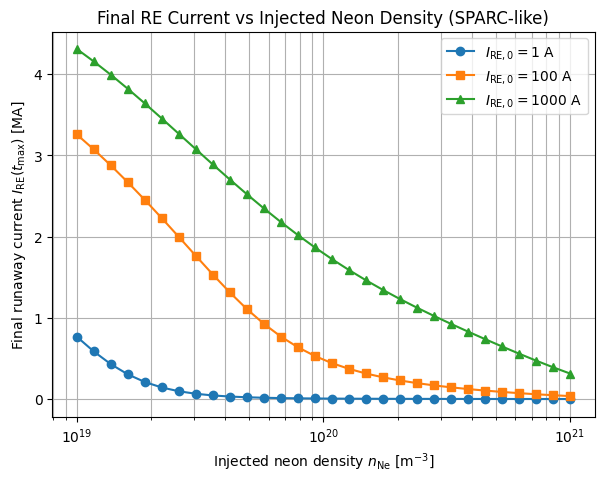

In [9]:
# neon density scan for SPARC-like
n_imp_scan = np.logspace(19, 21, 30)

def run_scan(seed_current):
    Irf = []

    for nimp in n_imp_scan:
        solver = solver0D()

        solver.Z_imp = 10
        solver.A_imp = 20
        solver.n_imp = nimp
        solver.Tf = 10
        solver.T0 = 20e3
        solver.nD = 18 * solver.n_imp
        solver.iDreicer = 0
        solver.tmax = 7e-3
        solver.Ir0 = seed_current
        
        # solve
        t, Ip, Ir, Wk = solver.solve()
        #  final runaway current
        Irf.append(Ir[-1])

    return np.array(Irf)


seed_values = [1, 100, 1000]  

Ir_1A    = run_scan(1)
Ir_100A  = run_scan(100)
Ir_1000A = run_scan(1000)

plt.figure(figsize=(7,5))

plt.semilogx(
    n_imp_scan,
    Ir_1A/1e6,
    'o-',
    label=r'$I_{\rm RE,0}=1$ A'
)

plt.semilogx(
    n_imp_scan,
    Ir_100A/1e6,
    's-',
    label=r'$I_{\rm RE,0}=100$ A'
)

plt.semilogx(
    n_imp_scan,
    Ir_1000A/1e6,
    '^-',
    label=r'$I_{\rm RE,0}=1000$ A'
)

plt.xlabel(r'Injected neon density $n_{\rm Ne}$ [m$^{-3}$]')
plt.ylabel(r'Final runaway current $I_{\rm RE}(t_{\max})$ [MA]')
plt.title('Final RE Current vs Injected Neon Density (SPARC-like)')

plt.grid(True, which='both')
plt.legend()

plt.show()

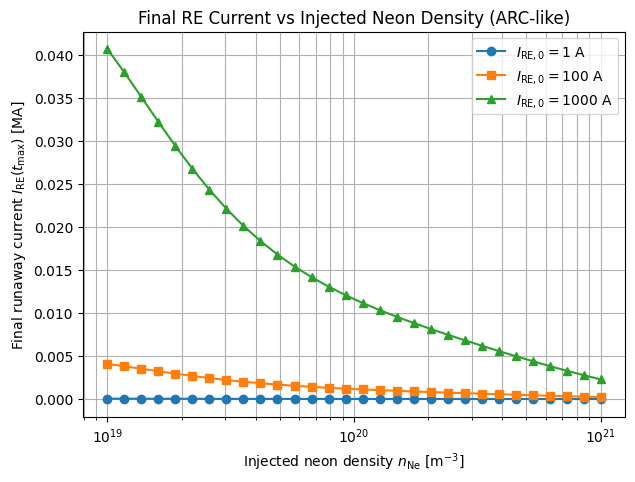

In [10]:
# neon density scan for ARC-like
n_imp_scan = np.logspace(19, 21, 30)

def run_scan(seed_current):
    Irf = []

    for nimp in n_imp_scan:
        solver = solver0D()

        solver.R0 = 4.68
        solver.a = 1.13
        solver.ni = 2e20
        solver.L = 2.972e-6 
        solver.k = 1.89

        solver.I0 = 12.0e6
        solver.Z_imp = 10
        solver.A_imp = 20
        solver.n_imp = nimp
        solver.Tf = 10
        solver.T0 = 20e3
        solver.t0 = 0.25e-3
        solver.nD = 18 * solver.n_imp
        solver.iDreicer = 0
        solver.tmax = 7e-3
        solver.Ir0 = seed_current
        
        # solve
        t, Ip, Ir, Wk = solver.solve()
        #  final runaway current
        Irf.append(Ir[-1])

    return np.array(Irf)


seed_values = [1, 100, 1000]  

Ir_1A    = run_scan(1)
Ir_100A  = run_scan(100)
Ir_1000A = run_scan(1000)

plt.figure(figsize=(7,5))

plt.semilogx(
    n_imp_scan,
    Ir_1A/1e6,
    'o-',
    label=r'$I_{\rm RE,0}=1$ A'
)

plt.semilogx(
    n_imp_scan,
    Ir_100A/1e6,
    's-',
    label=r'$I_{\rm RE,0}=100$ A'
)

plt.semilogx(
    n_imp_scan,
    Ir_1000A/1e6,
    '^-',
    label=r'$I_{\rm RE,0}=1000$ A'
)

plt.xlabel(r'Injected neon density $n_{\rm Ne}$ [m$^{-3}$]')
plt.ylabel(r'Final runaway current $I_{\rm RE}(t_{\max})$ [MA]')
plt.title('Final RE Current vs Injected Neon Density (ARC-like)')

plt.grid(True, which='both')
plt.legend()

plt.show()

## Hot tail Modeling: Sparc-like and Arc like

In [11]:
def getf(v, n0, vT0, tau):
    """
    Corrected Maxwellian with tau
    v: velocity (m/s)
    n0: density (m^-3)
    vT0: initial thermal speed (m/s)
    tau: no units
    returns:
    f : m^3 
    """
    prefactor = n0 / (np.pi**1.5 * vT0**3)
    expo = -((v**3/vT0**3) + 3*tau)**(2/3)
    return prefactor * np.exp(expo)

def getfm(v, n0, vT):
    """
    Basic one without tau
    v: velocity (m/s)
    n0: density (m^-3)
    vT: current thermal speed (m/s)
    returns:
    f : m^3 
    """
    prefactor = n0 / (np.pi**1.5 * vT**3)
    expo = -((v**2/vT**2))
    return prefactor * np.exp(expo)


def temperature(t, T0, Tf, t0):
    """
    Parameters:
    t: Time (s)
    T0: initial temp (eV)
    Tfinal: final temp (eV)
    t0: decay time (s)
    """
    return Tf + (T0 - Tf) * np.exp(-t / t0)

def getnu0(n, T0):
    """
    T: temp (joules)
    vT: initial time (s)
    returns rate in s^-1
    """
    vT0 = np.sqrt(2 * T0 * const.e / const.m_e) # m/s
    lnL = 15 
    return n*const.e**4 * lnL/(4*np.pi * const.epsilon_0**2 * const.m_e**2 * vT0**3)

def getTau(nu0, t, t0):
    """
    t0: initial time (s)
    t: time (s)
    nu0: collision rate (s^-1)
    returns:
    tau (no unit) 
    """
    return nu0 * max(0.0, t - t0)
    #return nu0 * max(0.0, t - 0)

def get_vc(T,E,ne):
    lnA = 15
    Ed = RE.getDreicerField(ne,lnA,T) # V/m
    vc2 = (T * const.e / const.m_e) * (Ed / E)
    return np.sqrt(vc2)

# define the hot-tail function

def getHT(n0,T0,E0,T,t,t0):
    # n0 [per cubic m] = density
    # T0 [eV] = initial temperature
    # T [eV] = temperature at time t
    # E0 [V/m] = initial E-field 
    # t [s] = time
    # t0 [s] = temp. decay time
    
    # thermal velocities
    vT0 = np.sqrt(2 * T0 * const.e / const.m_e) # m/s
    vT = np.sqrt(2 * T * const.e / const.m_e) # m/s
    
    # Collision freq.
    nu0 = getnu0(n0, T0)
    
    # get the distribution function
    x = np.linspace(0, 50, int(5e4))      # x = (v / vT0)^2
    v = np.sqrt(x)*vT0
    fm = getfm(v, n0, vT) # cold maxwellian
    tau = getTau(nu0, t, t0)
    f = getf(v, n0, vT0, tau) # hot population
    ftot = fm + f # total distribution
    
    # Electric field
    E = E0 * (T/T0)**(-3/2)
    vc = get_vc(T,E,n0) # m/s
    
    # Now integrate from vc to inf
    idx = np.argwhere(v >= vc)
    idx = idx.flatten()
    return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m
    

C:\Users\grace\AppData\Local\Temp\ipykernel_16364\3039273906.py:98: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


Text(0.5, 0, 't [ms]')

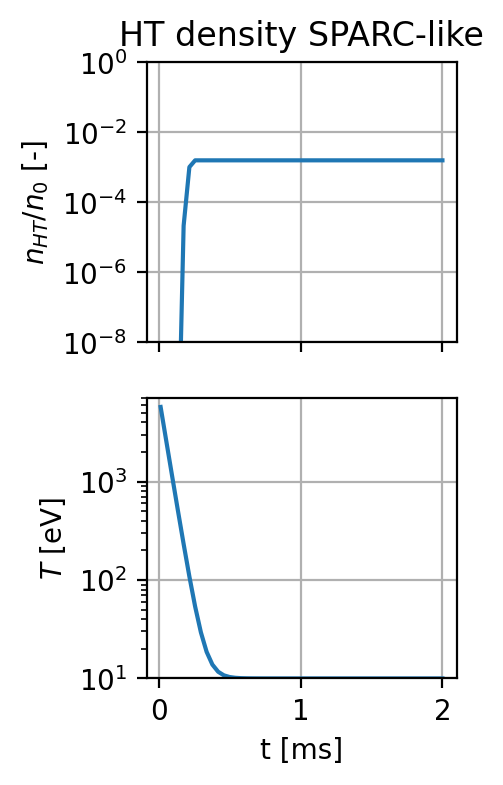

In [17]:
# SPARc like conditions 
T0 = 7e3     # eV
Tf = 10 # eV
t0 = 0.5e-4    # s
n0 = 3e20 # m^-3

Ip = 8.7e6 # ampere
a = 0.57 # m
k = 1.7
j = Ip / (np.pi * a**2 * k)
eta = 0.51 * RE.getTransSpitzerResistivity(15,T0,1) * 0.01
E0 = eta * j # V/m

t = np.linspace(1e-5,2e-3,50)
nht = np.zeros_like(t)

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    nht[ii] = getHT(n0,T0,E0,T,t[ii],t0)
    if (nht[ii] < nht[ii-1]):
        nht[ii] = nht[ii-1]


fig, axs = plt.subplots(2,1,sharex=True,figsize=(2,4),dpi=200)
axs[0].set_title("HT density SPARC-like")
axs[0].plot(t*1e3, nht/n0)
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8,1e0])
axs[0].grid()

axs[1].plot(t*1e3,temperature(t, T0, Tf, t0))
axs[1].set_yscale('log')
axs[1].set_ylabel('$T$ [eV]')
axs[1].set_ylim([Tf,T0])
axs[1].grid()
axs[-1].set_xlabel('t [ms]')
    

    
    


C:\Users\grace\AppData\Local\Temp\ipykernel_16364\3039273906.py:98: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


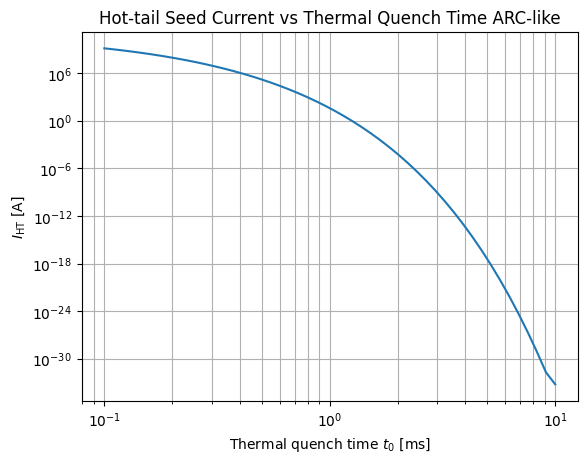

In [26]:
#HT current vs TQ time 
# Plasma area
area = np.pi * a**2 * k


#TQ times [s]
t0_scan = np.logspace(-4, -2, 50)   # 0.1 ms -> 10 ms

I_HT = np.zeros_like(t0_scan)

for i, t0 in enumerate(t0_scan):

    # Make sure it's final value
    t_eval = 10 * t0

    n_ht = getHT(
        n0=n0,
        T0=T0,
        E0=E0,
        T=Tf,
        t=t_eval,
        t0=t0
    )

    # HT density to current
    I_HT[i] = n_ht * const.e * const.c * area

#plt.figure(figsize=(5,4), dpi=200)

plt.loglog(t0_scan*1e3, I_HT)

plt.xlabel(r'Thermal quench time $t_0$ [ms]')
plt.ylabel(r'$I_{\rm HT}$ [A]')
plt.title('Hot-tail Seed Current vs Thermal Quench Time ARC-like')
plt.grid(True, which='both')

plt.show()

C:\Users\grace\AppData\Local\Temp\ipykernel_16364\3039273906.py:98: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


Text(0.5, 0, 't [ms]')

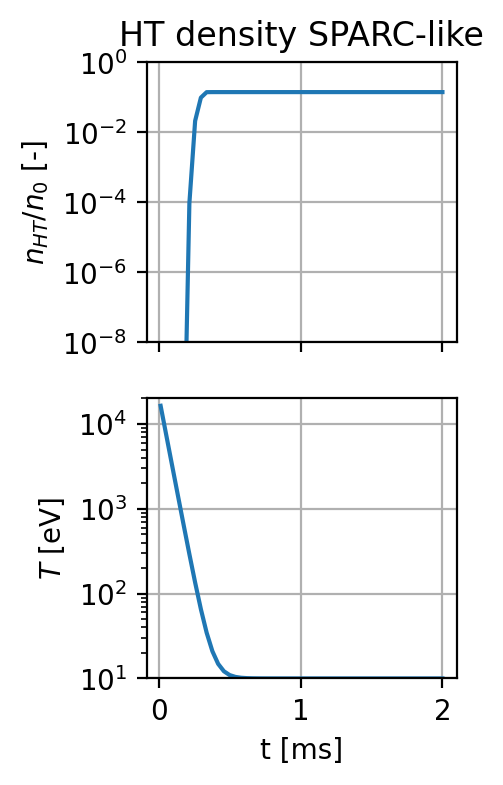

In [23]:
# ARC like 
T0 = 20e3     # eV
Tf = 10 # eV
t0 = 0.5e-4    # s
n0 = 2e20 # m^-3

Ip = 12.0e6 # ampere
a = 1.13 # m
k = 1.89
j = Ip / (np.pi * a**2 * k)
eta = 0.51 * RE.getTransSpitzerResistivity(15,T0,1) * 0.01
E0 = eta * j # V/m

t = np.linspace(1e-5,2e-3,50)
nht = np.zeros_like(t)

for ii in range(1,t.shape[0]):
    T = temperature(t[ii], T0, Tf, t0) # eV
    nht[ii] = getHT(n0,T0,E0,T,t[ii],t0)
    if (nht[ii] < nht[ii-1]):
        nht[ii] = nht[ii-1]


fig, axs = plt.subplots(2,1,sharex=True,figsize=(2,4),dpi=200)
axs[0].set_title("HT density SPARC-like")
axs[0].plot(t*1e3, nht/n0)
axs[0].set_ylabel('$n_{HT}/n_0$ [-]')
axs[0].set_yscale('log')
axs[0].set_ylim([1e-8,1e0])
axs[0].grid()

axs[1].plot(t*1e3,temperature(t, T0, Tf, t0))
axs[1].set_yscale('log')
axs[1].set_ylabel('$T$ [eV]')
axs[1].set_ylim([Tf,T0])
axs[1].grid()
axs[-1].set_xlabel('t [ms]')
    

    
    


C:\Users\grace\AppData\Local\Temp\ipykernel_16364\3039273906.py:98: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(4 * np.pi * (v[idx]**2-vc**2) * ftot[idx],v[idx]) # per cubic m


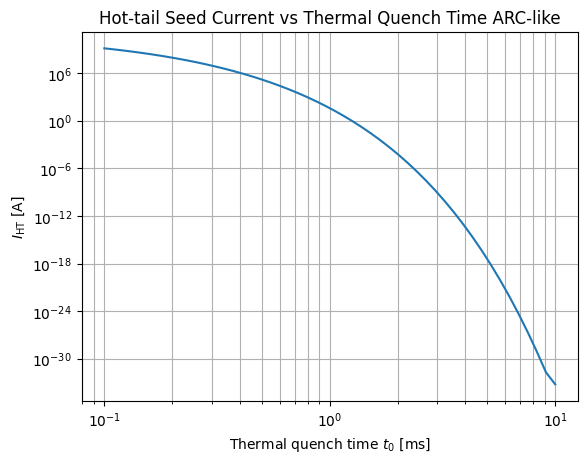

In [25]:
#HT current vs TQ time 
# Plasma area
area = np.pi * a**2 * k


#TQ times [s]
t0_scan = np.logspace(-4, -2, 50)   # 0.1 ms -> 10 ms

I_HT = np.zeros_like(t0_scan)

for i, t0 in enumerate(t0_scan):

    # Make sure it's final value
    t_eval = 10 * t0

    n_ht = getHT(
        n0=n0,
        T0=T0,
        E0=E0,
        T=Tf,
        t=t_eval,
        t0=t0
    )

    # HT density to current
    I_HT[i] = n_ht * const.e * const.c * area

#plt.figure(figsize=(5,4), dpi=200)

plt.loglog(t0_scan*1e3, I_HT)

plt.xlabel(r'Thermal quench time $t_0$ [ms]')
plt.ylabel(r'$I_{\rm HT}$ [A]')
plt.title('Hot-tail Seed Current vs Thermal Quench Time ARC-like')
plt.grid(True, which='both')

plt.show()